In [2]:
push!(LOAD_PATH,"./")
push!(LOAD_PATH,"julia/")
include("model.jl")
using Plots
using StatsPlots
using CSV
using DataFrames

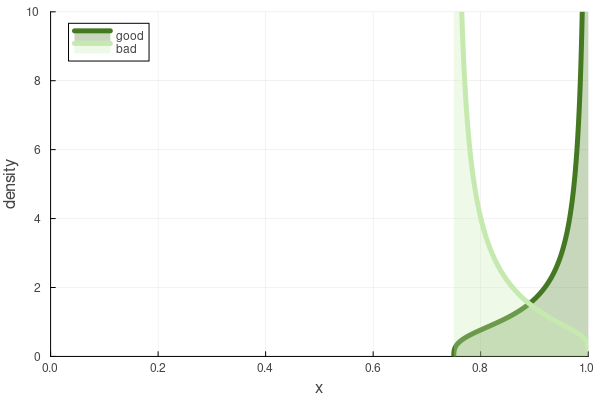

In [3]:
s = Strategy(1,0,0,1,1,0,0,0,0,0)
parameters = Dict("alpha" => 1, "beta" => 4, "lambda" => 1, "b" => 2, "c" => 1, "gamma" => 0, "delta" => 1e-6, "n" => 0)
w = solveModel(parameters,s)
default(fontfamily="Helvetica")
x = w.I[1]:0.0001:w.I[2]
plot(x,map(w.uA,x),xlims=(0,1),label="good",color="#447821",linewidth=5,xlabel="x",ylabel="density",ylims=(0,10),fillrange=0,fillalpha=0.3)
plot!(x,map(w.uB,x),label="bad",color="#C6E9AF",linewidth=5,fillrange=0,fillalpha=0.3)

In [7]:
for motif in ["I","II","spontaneous"]

    d = DataFrame(alpha = Float64[],beta  = Float64[],x= Float64[],y= Float64[], env = String[])
    for alpha in 1:10
        for beta in [0,0.1,0.4,1,4,10]
            parameters = Dict("alpha" => alpha, "beta" => beta, "lambda" => 1, "b" => 2, "c" => 1, "gamma" => 1, "delta" => 1e-6, "n" => 0)
            if motif == "I"
                s = Strategy(1,0,0,1,1,0,0,0,0,0)
            elseif motif == "II"
                s = Strategy(1,0,0,1,0,1,0,0,0,0)
            elseif motif == "spontaneous"
                s = Strategy(1,0,0,1,0,0,0,0,sqrt(8)-1,0)
            end
            w = solveModel(parameters,s)
            x = w.I[1]:0.0001:w.I[2]
            append!(d,DataFrame(alpha=alpha,beta=beta,x=x,y=map(w.uA,x),env="good"))
            append!(d,DataFrame(alpha=alpha,beta=beta,x=x,y=map(w.uB,x),env="bad"))
        end
    end

    CSV.write("results/motif_"*motif*"_examples.csv",d)

    d_mean = DataFrame(alpha = Float64[], beta=Float64[], b = Float64[], meanA = Float64[], meanB = Float64[])
    for alpha in 1:6
        for beta in 4
            for b in 2 .^ collect(-3:0.01:3)
                parameters = Dict("alpha" => alpha, "beta" => beta, "lambda" => 1, "b" => b, "c" => 1, "gamma" => 1, "delta" => 1e-6, "n" => 0)
                if motif == "I"
                    s = Strategy(1,0,0,1,1,0,0,0,0,0)
                elseif motif == "II"
                    s = Strategy(1,0,0,1,0,1,0,0,0,0)
                elseif motif == "spontaneous"
                    s = Strategy(1,0,0,1,0,0,0,0,sqrt(8)-1,0)
                end
                w = solveModel(parameters,s)
                append!(d_mean,DataFrame(alpha=alpha,beta=beta,b=b,meanA=w.meanA,meanB=w.meanB))
            end
        end
    end

    CSV.write("results/motif_"*motif*"_examples_means.csv",d_mean)
end

"results/interaction_examples_means.csv"

In [58]:
w.meanA

0.9277218407768992

In [69]:
abs(-5)

5

In [14]:
x = 0.01:0.01:0.99
map(w.uA, x)

99-element Vector{Float64}:
 0.07186976910045563
 0.08308709039460395
 0.09069290175658024
 0.0966993920721694
 0.10179126564646837
 0.10629050330474402
 0.11037617402477523
 0.11415894922947444
 0.11771244048548334
 0.12108835668289579
 ⋮
 1.1412130225640735
 1.26268915284946
 1.4160532224397222
 1.6163281485483034
 1.8899818973342206
 2.2886191694870663
 2.928909625574685
 4.14644287420982
 7.511537728273465

In [15]:
e = Environment(2,["bad","good"],[0 1; 1 0])
s = randomStrategy(2)

Strategy(2, 0.46176849430771805, 0.793239836931838, 0.4194425121337625, 0.6490703140570134, 0.6684174445632027, 0.32632679827526145, 0.43912897720595057, 0.6407981899153892)

In [16]:
a = analyzeStrategy(e, s, Dict("B" => 2.0, "C" => 1.0, "gamma" => 1e-6, "n" => 2, "alpha" => 3.0, "beta"=>1.0), allStates(e, 2))

Dict{String, Any} with 4 entries:
  "fitness"  => 0.193788
  "M"        => [-5.54708 4.54708 … 0.0 0.0; 1.8121 -5.24288 … 1.0 0.0; … ; 0.0…
  "analysis" => Dict{Any, Any}()
  "states"   => 6×10 DataFrame…

In [17]:
a["states"]

Row,A,B,env_state,env,activity,perCapitaYield,yield,timeSpent,fitnessContribution,leaveRate
,Int64,Int64,Int64,String,Int64,Float64,Float64,Float64,Float64,Float64
1,2,0,1,bad,2,-1.0,-2.0,0.0924182,-0.184836,5.54708
2,1,1,1,bad,1,-1.0,-1.0,0.235919,-0.235919,5.24288
3,0,2,1,bad,0,-1.0,-0.0,0.171663,-0.0,4.39491
4,2,0,2,good,2,2.0,4.0,0.0851414,0.340566,6.41209
5,1,1,2,good,1,2.0,2.0,0.233882,0.467765,5.80236
6,0,2,2,good,0,2.0,0.0,0.180976,0.0,4.64887


In [20]:
allStates(e,3)["envloc"]

Dict{Any, Any} with 4 entries:
  4 => Any[4, 8]
  2 => Any[2, 6]
  3 => Any[3, 7]
  1 => Any[1, 5]

In [32]:
function states(n)
    d = DataFrame(typeA = repeat(0:n, 2),
    environment = vcat(fill("A", n+1), fill("B", n+1)))
    d.typeB = n .- d.typeA
    return d 
end

states (generic function with 1 method)

In [33]:
states(5)

Row,typeA,environment,typeB
,Int64,String,Int64
1,0,A,5
2,1,A,4
3,2,A,3
4,3,A,2
5,4,A,1
6,5,A,0
7,0,B,5
8,1,B,4
9,2,B,3


In [19]:
function createSystemMarkovChain(n, alpha, beta, gamma, lambda, s)
    m = zeros(2*n+2, 2*n+2)
    for i in 1:(n+1)
        m[i,i] += -lambda
        m[n+1+i, i] += lambda
        m[n+1+i, n+1+i] += -lambda
        m[i, n+1+i] += lambda
    end
    function pIncreaseA(x,env) # probability for A to increase given x individuals in env
        if env == "A"
            return alpha*(n-x)*s.piAA + beta*x*(n-x)*s.thetaAA + beta*(n-x)*(n-x)*s.thetaBA + (n-x)*gamma
        elseif env == "B"
            return alpha*(n-x)*s.piBA + beta*x*(n-x)*s.thetaAA + beta*(n-x)*(n-x)*s.thetaBA + (n-x)*gamma
        end
    end
    function pDecreaseA(x, env)
        if env == "A"
            return alpha*x*s.piAB + beta*x*(n-x)*s.thetaBB + beta*x*x*s.thetaAB + x*gamma
        elseif env == "B"
            return alpha*x*s.piBB + beta*x*(n-x)*s.thetaBB + beta*x*x*s.thetaAB + x*gamma
        end    
    end
    for i in 1:(n)
        m[i,i+1] += pDecreaseA(i, "A")
        m[i+1, i+1] += -pDecreaseA(i, "A")
        m[i+1,i] += pIncreaseA(i-1, "A")
        m[i,i] += -pIncreaseA(i-1, "A")
        m[n+1+i,n+1+i+1] += pDecreaseA(i, "B")
        m[n+1+i+1,n+1+i+1] += -pDecreaseA(i, "B")
        m[n+1+i+1,n+1+i] += pIncreaseA(i-1, "B")
        m[n+1+i,n+1+i] += -pIncreaseA(i-1, "B")
    end
    return m
end

createSystemMarkovChain (generic function with 2 methods)

In [1]:
struct Strategy
    piAA::Float64
    piAB::Float64
    piBA::Float64
    piBB::Float64
    thetaAA::Float64
    thetaAB::Float64
    thetaBA::Float64
    thetaBB::Float64
end

In [24]:
m1 = createSystemMarkovChain(4, 1, 0, 0.001, 1, Strategy(1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0))

10×10 Matrix{Float64}:
 -5.004   0.001   0.0     0.0     0.0    …   0.0     0.0     0.0     0.0
  4.004  -4.004   0.002   0.0     0.0        1.0     0.0     0.0     0.0
  0.0     3.003  -3.004   0.003   0.0        0.0     1.0     0.0     0.0
  0.0     0.0     2.002  -2.004   0.004      0.0     0.0     1.0     0.0
  0.0     0.0     0.0     1.001  -1.004      0.0     0.0     0.0     1.0
  1.0     0.0     0.0     0.0     0.0    …   1.001   0.0     0.0     0.0
  0.0     1.0     0.0     0.0     0.0       -2.004   2.002   0.0     0.0
  0.0     0.0     1.0     0.0     0.0        0.003  -3.004   3.003   0.0
  0.0     0.0     0.0     1.0     0.0        0.0     0.002  -4.004   4.004
  0.0     0.0     0.0     0.0     1.0        0.0     0.0     0.001  -5.004

In [27]:
using LinearAlgebra
function stationaryState(mat)
    #println(mat)
    n = nullspace(mat)
    if size(n,2) > 1
        println(mat)
        u = findfirst(i -> sameSign(n[:,i]),1:size(n,2)) # there may be multiple columns; find the first column where all entries have the same sign
        n = n[:,u]
    end
    s = n / sum(n)
    return(vec(s))
end


stationaryState (generic function with 1 method)

In [47]:

function fitnessFiniteModel(n,alpha,beta,gamma,lambda,s,yA,yB)
    m = createSystemMarkovChain(n, alpha, beta, gamma, lambda, s)
    v = stationaryState(m)
    return sum(v .* [collect(0:n) .* yA ;  reverse(collect(0:n)) .* yB])/n
end

fitnessFiniteModel (generic function with 1 method)

In [6]:
fitnessFiniteModel(1, 3, 100, 0.001, 1, Strategy(1,0,0,1,1,0,0,0), 1, 1)

0.7998800479808079

In [46]:
n = 4 
yA = 1
yB = 1
[collect(0:n) .* yA ;  reverse(collect(0:n)) .* yB]

10-element Vector{Int64}:
 0
 1
 2
 3
 4
 4
 3
 2
 1
 0

In [12]:
using DataFrames
using Plots

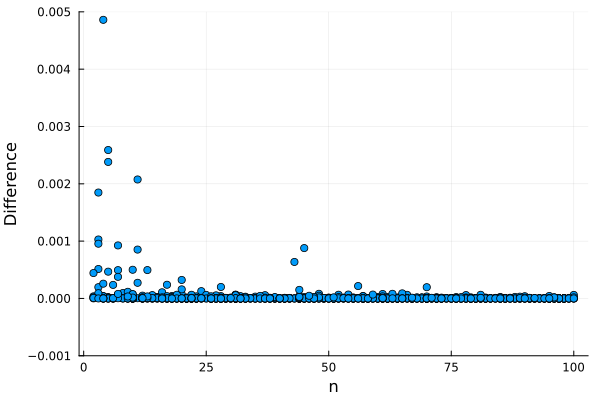

In [ ]:
using DataFrames
using Plots
d = DataFrame(alpha = [], beta = [], n = [], piAA = [], piAB = [], piBA = [], piBB = [], thetaAA = [], thetaAB = [], thetaBA = [], thetaBB =[], f1=[], f2=[])
for i in 1:1000
    s = Strategy(rand(),rand(),rand(),rand(),rand(),rand(),rand(),rand())
    alpha = rand()*50
    beta = rand()*5
    lambda = 1
    gamma = 0
    yA = 1
    yB = 1
    n = rand(2:100)
    f1 = fitnessInfiniteModel(alpha,beta,lambda,s,yA,yB)
    f2 = fitnessFiniteModel(n,alpha,beta,gamma,lambda,s,yA,yB)
    if abs(f1-f2) > 0.01
        println(n)
    end
    push!(d, (alpha=alpha, beta=beta, n =n, piAA = s.piAA, piAB = s.piAB, piBA= s.piBA, piBB=s.piBB, thetaAA=s.thetaAA,thetaAB=s.thetaAB, thetaBA=s.thetaBA, thetaBB=s.thetaBB, f1=f1, f2=f2))
end
scatter(d.n,abs.(d.f1-d.f2),ylims=(-0.001,0.005),label="",xlab="n",ylab="Difference")

In [76]:
f1

0.49706802333601807

In [85]:
minimum(f1s .- f2s)

-0.018261196508140676

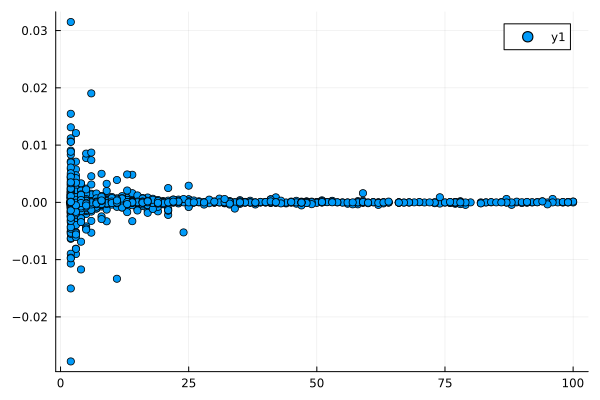

In [69]:
floor(100^rand())

46.0

In [40]:
vcat([0,1,2,3,4],[4,3,2,1,0])

10-element Vector{Int64}:
 0
 1
 2
 3
 4
 4
 3
 2
 1
 0

In [37]:
(0:n) .* yB

0:1:4